# Quantum Metal tutorial 4.43 — the 10 × 10 bare-paddle transmon array of the package-mode study (Quantcore PDK rebuild)

**What the chip is.** The Qiskit Metal tutorial `docs/tut/4-Analysis/4.43-Mesh-and-solve-the-10x10-processor.ipynb`;
the layout is `pm.build_design()` in `docs/tut/resources/package_modes/package_modes.py` (shared by tutorials
4.41–4.46), © Qiskit Metal contributors, Apache-2.0 (<https://github.com/qiskit-community/qiskit-metal>). The device
is the validation processor of R. Molavi *et al.*, "Extracting electromagnetic bare mode couplings in large
superconducting quantum processors", arXiv:2609.22442 (2026), Fig. 4; spec `docs/designs/metal/tut443_10x10_package.md`.
We distribute the rebuild under GPL-3.0. 100 bare transmons, each two 0.5 × 1 mm paddles side by side along x
across a 0.2 mm junction gap, on a 3 mm pitch ((i + 0.5)·3, (j + 0.5)·3) mm, on a 30 × 30 mm chip with **no ground
plane** (0.5 mm silicon in a 30 × 30 × 3 mm metal box). No routes, resonators or ports: it is a package-mode study.

**This notebook rebuilds it with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`): the
chip, the stack, the junctions, the netlist and the LOM are ours.

| | Qiskit Metal 4.43 (`package_modes.py`) | Quantcore PDK rebuild |
|---|---|---|
| chip | 30 × 30 mm, spanning 0…30 mm (Designer = Metal + (0, 0)) | the same 30 × 30 mm box with the QCT die frame |
| substrate | 0.5 mm silicon in a 3 mm metal box | sapphire 650 µm, εr 10.25 (LOM and FEM; the FEM box is the PDK's, not the 3 mm lid) |
| ground plane | none | a chip-wide etch (`metal:Rectangle`, `subtract`) stopping 0.7 mm inside the die edge, so the frame's dicing L's and alignment grids sit in ground metal (the paddles start 1.25 mm from the edge) |
| pads | none | none (nothing for the pad rule to move) |
| qubits | the resource module's own `TwoPadTransmon` (defined inside a function, not importable) | qcc's `TwoPadTransmon`, its geometric twin: `pad_thickness` 500, `pad_height` 1000, `gap` 200, no leads (`a = 0`), no pocket (`pocket_margin = 0`) |
| junctions | a lumped element (a 20 µm junction-table line, no metal; the paper's fit 3.63 nH) | a Quantcore trilayer junction drawn across each 200 µm gap, sized by the PDK rule for 4.05 GHz: L_J ≈ 5.34 nH, C_J ≈ 19 fF, R_n ≈ 36 kΩ (just below the 40–50 kΩ window: flagged) |
| cheese | none (no GDS export) | the PDK band (chip `cheese: "auto"`): with no ground plane only the 0.7 mm rim round the etch has ground to cheese |
| placement | as drawn | content centred in the die (already centred) |

**Kept exactly:** positions, paddle sizes, gap, orientation and the chip size.

**Not reproduced:** the tutorial's gmsh + scikit-fem Maxwell solve of the package mode (7.07 GHz empty box,
6.49 GHz with silicon, 6.48 GHz with paddles) and its electrostatics (≈ 174 fF across each junction). qcc's LOM has
no package modes, and its FEM export uses the PDK's stack, not the 3 mm lid (step 11).

The notebook goes step by step: PDK → die → (pads) → components → centring → DRC → netlist → LOM → FEM job →
results back → one change re-simulated → fab export → snapshots → summary (there are no routes: step 6 is short).

## 1 · Setup

The imports, the output folder and the `LIVE` switch: with KLayout open (the default), every step below is pushed to
the KLayout window as you run it; with `QCC_LIVE=0` the notebook builds headless and only writes files. `_common`
holds the small helpers the design notebooks share (tables, snapshots, the PDK placement and fab helpers).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK placement and fab helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/metal")             # this notebook's design JSON and PNG snapshots
# package_modes.DEVICE (mm): n, pitch, paddle, gap, chip
N, PITCH, PAD_W, PAD_H, GAP, L = 10, 3000, 500, 1000, 200, 30000
PAPER = {"C_qubit_fF": 173.8, "f_box_pads_GHz": 6.48}  # zfit_q00 C_n; package mode with paddles

## 2 · The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this chip that means: the 30 mm box gets the QCT frame; there are no pads for the pad rule; every qubit gets a trilayer junction across its gap, sized by the PDK rule; the cheese band only finds ground in the rim round the chip-wide etch.

In [3]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## 3 · The die and its frame

`Designer(name, box=...)` opens an empty chip. The box is the die (µm); the PDK draws the **QCT frame** on it: L
dicing markers in the four corners (1000/0), a 3 × 3 alignment grid in each corner area (1001/0), the chip boundary
(100/0) and the device ID `name_chip` on a free edge (optional: no free edge, no ID). The source's chip spans
0…30 mm, so Designer = Metal + (0, 0).

**No ground plane.** The source has none: the paddles see the box floor through the substrate. A chip-sized
`metal:Rectangle` with `subtract: true` etches the ground away, 0.7 mm inside the die edge so the frame markers stay
in ground metal; the paddles' metal is drawn over it.

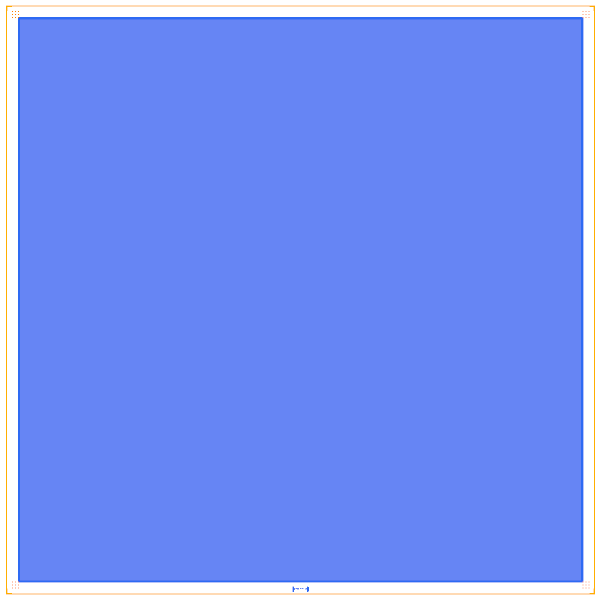

WindowsPath('examples/designs/metal/tut443_10x10_package_step_die.png')

In [4]:
d = Designer("tut443_10x10_package", box=(0, 0, L, L), chip={"name_chip": "MetalTut443"}, live=LIVE)
with d.batch():
    d.add("no_ground", "metal:Rectangle", at=(L / 2, L / 2), width=L - 1400, height=L - 1400, subtract=True)   # no ground plane (inside the PDK frame)
rebuild(d)                                       # a no-op when LIVE: it is already built
snap(d, OUT / "tut443_10x10_package_step_die.png", size=(600, 600), width=300)

## 4 · Pads

The package-mode study has no launchpads, readouts or control lines, so the PDK pad rule (outer etch edge 25 µm from
the die edge) has nothing to place; `pads_md(d)` in step 7 confirms there are none.

## 5 · Components: 100 two-paddle transmons with trilayer junctions

**The qubit.** The source's `TwoPadTransmon` lives inside a function of its resource module (not an importable
`metal:` class). Its exact geometric twin is qcc's `TwoPadTransmon` (the legacy two-pad transmon) with
`pad_thickness = 500`, `pad_height = 1000`, `gap = 200`, no leads (`a = 0`) and no pocket (`pocket_margin = 0`): two
rectangles whose metal is `base_metal_addition`. Its ports `left` / `right` (pad edges) are unused.

**The junction.** `TwoPadTransmon` takes `junction_type="Quantcore Junction"` + `junction_params`, so the PDK
trilayer junction is drawn across the 200 µm pad gap. The source's value (the paper's fit, 3.63 nH) is below what the
PDK window gives, so the junction is sized by the PDK rule for **4.05 GHz** (the bottom of the PDK band) with the
C_Σ ≈ 261 fF this design's LOM gives across the gap: `size_junction` returns the fingers, R_n, L_J and C_J. Here
R_n ≈ 36 kΩ, just below the 40–50 kΩ window: the DRC flags it (`pdk_rn`), it is not retuned. `junction=` carries the
drawn junction's L_J / C_J to the LOM and the FEM junction port. (This replaces the earlier to-do note that the
junction was only assumed in the LOM.)

{'Lj_nH': 5.3448, 'Cj_fF': 18.9} R_n 35.6 kΩ, fingers 0.63 × 0.6 µm; R_n 35.6 kΩ is outside the process window 40–50 kΩ (f_q 4.05 GHz with C_Σ 279.8 fF needs E_J/h 30.6 GHz)
Q_0_0 ports: ['left', 'right', 'squid_a', 'squid_b']


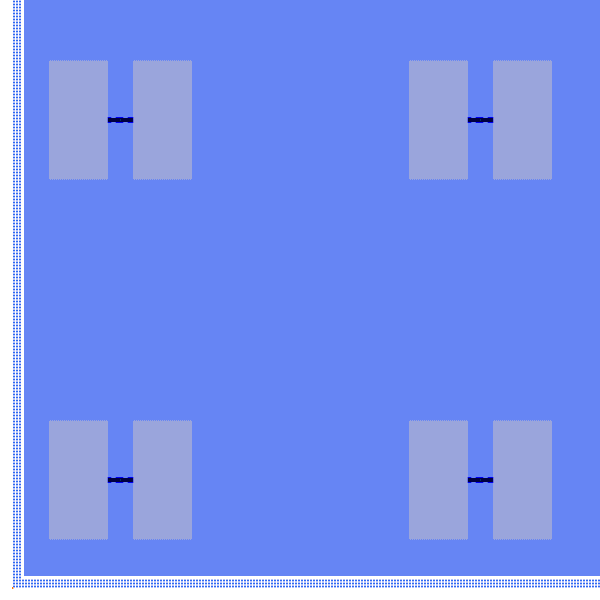

WindowsPath('examples/designs/metal/tut443_10x10_package_step_parts.png')

In [5]:
from quantcore_circuits.circuit.bridges import size_junction
# Quantcore trilayer junction drawn in each 200 µm gap (TwoPadTransmon junction_type), sized by the PDK rule
# for 4.05 GHz (bottom of the PDK band) with C_Σ ≈ 261 fF across the gap (this design's LOM before the rebuild)
SIZED = size_junction(4.05, 260.9, c_includes_junction=False)
JUNCTION = SIZED.design_junction()
print(JUNCTION, f"R_n {SIZED.rn_kohm:.1f} kΩ, fingers {SIZED.finger_width} × {SIZED.second_finger_width} µm;", *SIZED.notes)
with d.batch():
    for i in range(N):
        for j in range(N):
            d.add(f"Q_{i}_{j}", "TwoPadTransmon", at=((i + 0.5) * PITCH, (j + 0.5) * PITCH), junction=JUNCTION,
                  junction_type="Quantcore Junction", junction_params={"lj_nH": JUNCTION["Lj_nH"]},   # 5.3448 nH
                  pad_thickness=PAD_W, pad_height=PAD_H, gap=GAP, a=0, lead_length=0, pocket_margin=0)
print("Q_0_0 ports:", sorted(d["Q_0_0"].ports))
snap(d, OUT / "tut443_10x10_package_step_parts.png", box=(500, 500, 5500, 5500), size=(600, 600), width=300)

## 6 · Routes and sim groups

There are no routes: the 100 qubits couple only through the package modes and their (small) cross-capacitances. The
**sim groups** name what a FEM job cuts out: qubit (0, 0) alone (its capacitance across the junction) and the 2 × 2
corner (the cross-capacitances), each with a 1 mm margin, for Q3D C-matrix jobs.

In [6]:
# FEM: qubit (0, 0) alone (its C across the junction), and the 2 × 2 corner (cross-capacitances)
d.sim_group("Q_0_0", ["Q_0_0"], margin_um=1000, analyses=["q3d_cmatrix"])
d.sim_group("corner", ["Q_0_0", "Q_1_0", "Q_0_1", "Q_1_1"], margin_um=1000, analyses=["q3d_cmatrix"])
print(sorted(d.data["sim_groups"]))

['Q_0_0', 'corner']


## 7 · Centre the content and save

The PDK wants the chip content centred in the die. `center_in_die` measures the bounding box of everything placed
and shifts the design so its centre is the die centre. The array and the chip-wide etch are symmetric about the die
centre, so nothing moves. Then the design is saved: the JSON is the deliverable.

In [7]:
shift = center_in_die(d)
rebuild(d)
print("content shifted by", shift, "µm")
display(Markdown(pads_md(d)))
DESIGN = d.save(OUT / "tut443_10x10_package.json")
print(d, "→", DESIGN)

content shifted by (0.0, 0.0) µm


| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| – | no bond pads or launchers | – | – | – |

<Designer tut443_10x10_package: 101 instances, 0 routes, live=False> → examples\designs\metal\tut443_10x10_package.json


## 8 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip
box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning: the values are the source's.

Expected here: **no errors**; 400 `dangling_port` warnings (each qubit's unused `left` / `right` pad edges and
its junction refpoints `squid_a` / `squid_b`: nothing is wired on this chip); 100 `overlap` warnings (the qubits on
the chip-wide `no_ground` etch, by design); and **100 PDK design warnings `pdk_rn`** (R_n ≈ 36 kΩ, below the
40–50 kΩ window, because the junction is sized for 4.05 GHz on the large paddle capacitance).

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings.

In [8]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

**0 errors · 500 warnings · 100 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 400 | Q_0_0.left is not connected (no route or snap) |
| warning | `overlap` | 100 | Q_0_0 and no_ground overlap |
| PDK design warning | `pdk_rn` | 100 | Q_0_0: junction R_n 35.7 kΩ is outside the PDK window 40–50 kΩ (L_J 5.3448 nH) |

| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Junction × 100 |
| PDK design warnings | 100 (pdk_rn × 100) |
| pdk_rn | Q_0_0: junction R_n 35.7 kΩ is outside the PDK window 40–50 kΩ (L_J 5.3448 nH) |
| pdk_rn | Q_0_1: junction R_n 35.7 kΩ is outside the PDK window 40–50 kΩ (L_J 5.3448 nH) |
| pdk_rn | Q_0_2: junction R_n 35.7 kΩ is outside the PDK window 40–50 kΩ (L_J 5.3448 nH) |
| pdk_rn | Q_0_3: junction R_n 35.7 kΩ is outside the PDK window 40–50 kΩ (L_J 5.3448 nH) |
| pdk_rn | Q_0_4: junction R_n 35.7 kΩ is outside the PDK window 40–50 kΩ (L_J 5.3448 nH) |
| pdk_rn | Q_0_5: junction R_n 35.7 kΩ is outside the PDK window 40–50 kΩ (L_J 5.3448 nH) |
| pdk_rn | Q_0_6: junction R_n 35.7 kΩ is outside the PDK window 40–50 kΩ (L_J 5.3448 nH) |
| pdk_rn | Q_0_7: junction R_n 35.7 kΩ is outside the PDK window 40–50 kΩ (L_J 5.3448 nH) |
| pdk_rn | Q_0_8: junction R_n 35.7 kΩ is outside the PDK window 40–50 kΩ (L_J 5.3448 nH) |
| pdk_rn | Q_0_9: junction R_n 35.7 kΩ is outside the PDK window 40–50 kΩ (L_J 5.3448 nH) |
| pdk_rn | Q_1_0: junction R_n 35.7 kΩ is outside the PDK window 40–50 kΩ (L_J 5.3448 nH) |
| pdk_rn | Q_1_1: junction R_n 35.7 kΩ is outside the PDK window 40–50 kΩ (L_J 5.3448 nH) |

## 9 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit: each `TwoPadTransmon` gives two floating islands (`island1` left
paddle, `island2` right paddle), each with an analytic C to ground, C between them across the gap, and the junction.
Nothing couples the 100 qubits in the LOM: in the source they couple only through the package modes and their
(small) cross-capacitances, which the corner Q3D job gives. The first rows only, then Q_0_0's capacitances:

In [9]:
from collections import Counter
lb = d.lom()
md_ = netlist_md(lb)
display(Markdown("\n".join(md_.splitlines()[:12]) + "\n\n…\n\n" + "\n".join(l for l in md_.splitlines() if "Q_0_0" in l and l.startswith("| `C"))))
print(Counter(b.type for b in lb.model.branches.values()))
print({k: v for k, v in lb.port_map.items() if k.startswith("Q_0_0.")})

**201 nodes · 400 branches · 0 controls · 200 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `Q_0_0.island1` | `Q_0_0.island1` |
| `Q_0_0.island2` | `Q_0_0.island2` |
| `Q_0_1.island1` | `Q_0_1.island1` |
| `Q_0_1.island2` | `Q_0_1.island2` |
| `Q_0_2.island1` | `Q_0_2.island1` |
| `Q_0_2.island2` | `Q_0_2.island2` |
| `Q_0_3.island1` | `Q_0_3.island1` |

…

| `C_Q_0_0_1` | C | `Q_0_0.island1` – `gnd` | 408 fF |
| `C_Q_0_0_2` | C | `Q_0_0.island2` – `gnd` | 408 fF |
| `C_Q_0_0_12` | C | `Q_0_0.island1` – `Q_0_0.island2` | 56.8 fF |

Counter({'C': 300, 'JJ': 100})
{'Q_0_0.left': 'Q_0_0.island1', 'Q_0_0.right': 'Q_0_0.island2', 'Q_0_0.squid_a': 'Q_0_0.island1', 'Q_0_0.squid_b': 'Q_0_0.island2'}


## 10 · LOM simulation

Qubit (0, 0) alone (all 100 are identical and uncoupled in the LOM). QuCat gives its linear mode; QuTiP the dressed
f_q and α.

- With the PDK junction sized for 4.05 GHz, Q_0_0 lands at the bottom of the PDK band by construction.
- **The LOM overestimates C here:** qcc's `TwoPadTransmon` model puts its pads in a 50 µm pocket of a ground plane
  (≈ 408 fF per pad to ground), but this chip has no ground plane: the paddles see the box floor through 0.5 mm of
  silicon. The paper's impedance fit gives C_n = 173.8 fF (the tutorial's electrostatics ≈ 174 fF); with that C the
  same junction would put the qubit near 5 GHz. Request for lom (a no-ground-plane case); the Q3D job of step 11
  replaces the C by net name.

In [10]:
res = simulate_groups(d, {"Q_0_0": ["Q_0_0"]})
display(Markdown(modes_md(res["Q_0_0"]) + "\n\n" + groups_md(res)))
br = lb.model.branches
c1, c2, c12 = (br[f"C_Q_0_0_{k}"].value["estimate"] for k in ("1", "2", "12"))
c_across = c12 + c1 * c2 / (c1 + c2)
print(f"LOM C across the junction: {c_across:.0f} fF (paper's fit {PAPER['C_qubit_fF']} fF)")

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q_0_0 | qubit | 4.1163 | 0 | 69.3 | J_Q_0_0 1.00 |

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q_0_0 | Q_0_0 | 4.0458 | -72.09 | – | – | – | – |

LOM C across the junction: 261 fF (paper's fit 173.8 fF)


## 11 · FEM: send the job

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (the box set by `sim_group`), puts ports where lines leave the box and writes a job folder under
`build/jobs/`. Simulation exports never get cheese, and airbridges are dropped unless asked for.

Q3D C-matrix jobs for qubit (0, 0) and for the 2 × 2 corner: they replace the LOM's paddle estimates by net
name. They use the PDK's substrate and vacuum box, not the source's 0.5 mm silicon in a 3 mm box, so they do not
reproduce the package mode; the tutorial's own solver (`package_modes.py`) does that.

`RUN_FEM = False` keeps the notebook fast. Set it to `True` to solve the jobs here: `send_fem_jobs` finds AEDT 2024
R1 (or newer) and solves each Ansys job in a **new batch, non-graphical** AEDT, so an AEDT window you have open is
never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [11]:
jobs = export_sims(DESIGN, ["Q_0_0", "corner"])
display(Markdown(jobs_md(jobs)))

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| Q_0_0 | `build/jobs/tut443_10x10_package_Q_0_0_q3d_cmatrix` | 1 · junction · `Q_0_0.junction` | `Q_0_0.island1`, `Q_0_0.island2` |
| corner | `build/jobs/tut443_10x10_package_corner_q3d_cmatrix` | 1 · junction · `Q_0_0.junction`<br>2 · junction · `Q_1_0.junction`<br>3 · junction · `Q_0_1.junction`<br>4 · junction · `Q_1_1.junction` | `Q_0_0.island1`, `Q_1_0.island1`, `Q_0_1.island1`, `Q_1_1.island1`, `Q_0_0.island2`, `Q_1_0.island2`, `Q_0_1.island2`, `Q_1_1.island2` |

In [12]:
RUN_FEM = False   # True: solve the jobs now in a new batch AEDT (2024 R1 or newer)
if RUN_FEM:
    send_fem_jobs(DESIGN, ['Q_0_0', 'corner'], run=True)

## 12 · Bring the FEM results back

When a job has been solved, its folder holds `results/results.json`. `fem_back` fills the LOM with the extracted
C-matrix (matched by net name: the job's nets are the LOM's nodes) and lists each capacitance as estimate vs
extracted. Without results it says what would appear; the LOM values above stay the estimates.

In [13]:
filled, back_md = fem_back(lb.model, DESIGN, {f"{g} · q3d": v for g, v in jobs.items()})
display(Markdown(back_md))
for key, fc in filled.items():                   # re-simulate the LOM on the extracted values
    display(Markdown(f"**{key}, LOM on the FEM values:**"))
    display(Markdown(modes_md(simulate(fc))))

No FEM results yet for Q_0_0 · q3d, corner · q3d: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 13 · Iterate: change one property and re-simulate

A design loop in one cell: copy the saved design (`design_copy`: a non-live Designer that never writes over the
JSON), change one property — here Q_0_0's paddles, `pad_height` 1000 → 800 µm — rebuild, re-run the LOM of Q_0_0
and compare. Smaller paddles have less capacitance: E_C grows, so f_q and |α| go up.

In [14]:
d2 = design_copy(DESIGN)
d2["Q_0_0"].set(pad_height=800)                  # 1000 → 800 µm
after = simulate_groups(d2, {"Q_0_0": ["Q_0_0"]})
display(Markdown(params_delta_md(res, after)))

| parameter | before | after | Δ |
|---|---|---|---|
| `Q_0_0: Q_0_0.f_q_GHz` | 4.0458 | 4.3758 | +0.33 |
| `Q_0_0: Q_0_0.alpha_MHz` | -72.095 | -84.887 | -12.79 |

## 14 · Build and export

The design JSON saved in step 7 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it.
The fab export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer,
100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the cheese.

**Cheese.** Tutorial 4.43 never exports a GDS, so the original has no cheese: the PDK band applies
(`cheese: "auto"`, the default). With no ground plane the band only finds ground in the 0.7 mm rim between the
chip-wide etch and the frame (it is never drawn over etched, empty ground); the build draws it into KQC's
`ground_grid` layer and `export_fab` keeps it (`cheese source: build`).

Command-line equivalents:
- `qcc build examples/designs/metal/<id>.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/metal/<id>.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/metal/<id>.json -g <group> -a q3d_cmatrix` (one FEM job).

In [15]:
print("design file:", DESIGN)
CHEESE = True
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

design file: examples\designs\metal\tut443_10x10_package.json


| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 13838 |
| 2/0 | JJ_STRAIGHT | 100 |
| 3/0 | M3 | 13829 |
| 4/0 | JJ_BENT | 100 |
| 50/0 | HSQ | 200 |
| 51/0 | SPACER_1 | 200 |
| 52/0 | SPACER_2 | 200 |
| 53/0 | SPACER_3 | 200 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 13826 holes on the mask.

→ `build/tut443_10x10_package_fab.oas`

## 15 · Snapshots

The full chip and the corner Q_0_0 … Q_1_1 (compare the tutorial's two `qm.view` panels); qubit (0, 0)'s junction
gap with the trilayer junction; the **fab mask** at the west rim beside Q_0_0 (the cheese band in the ground rim,
the chip-wide etch, the left paddle); and the die frame's south-west corner (dicing L on 1000/0, alignment grid on
1001/0). Positions are read from the design.

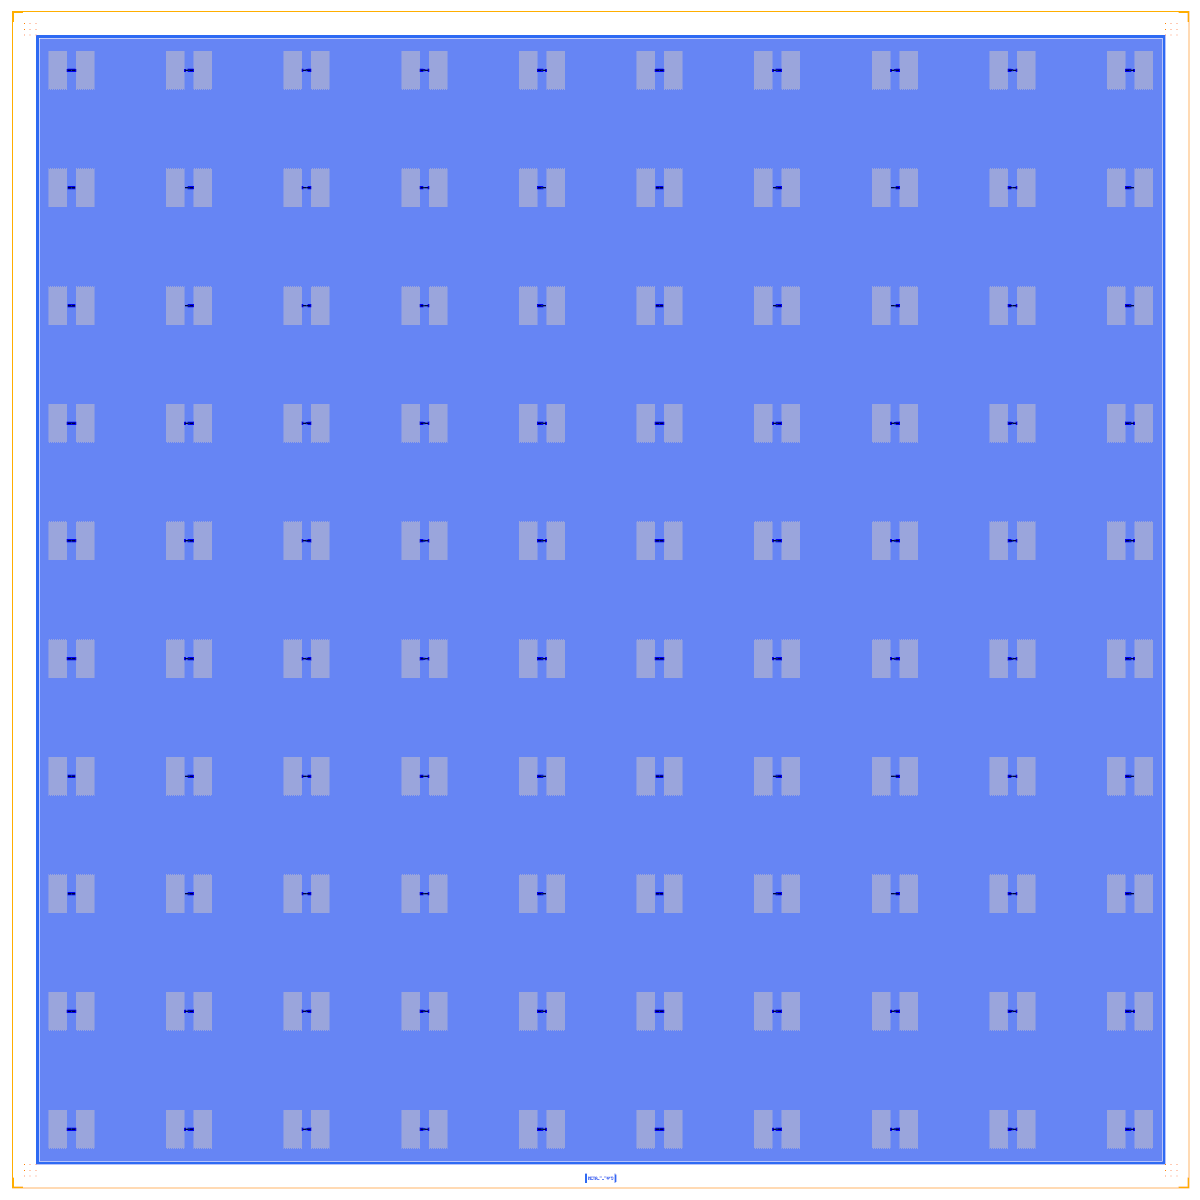

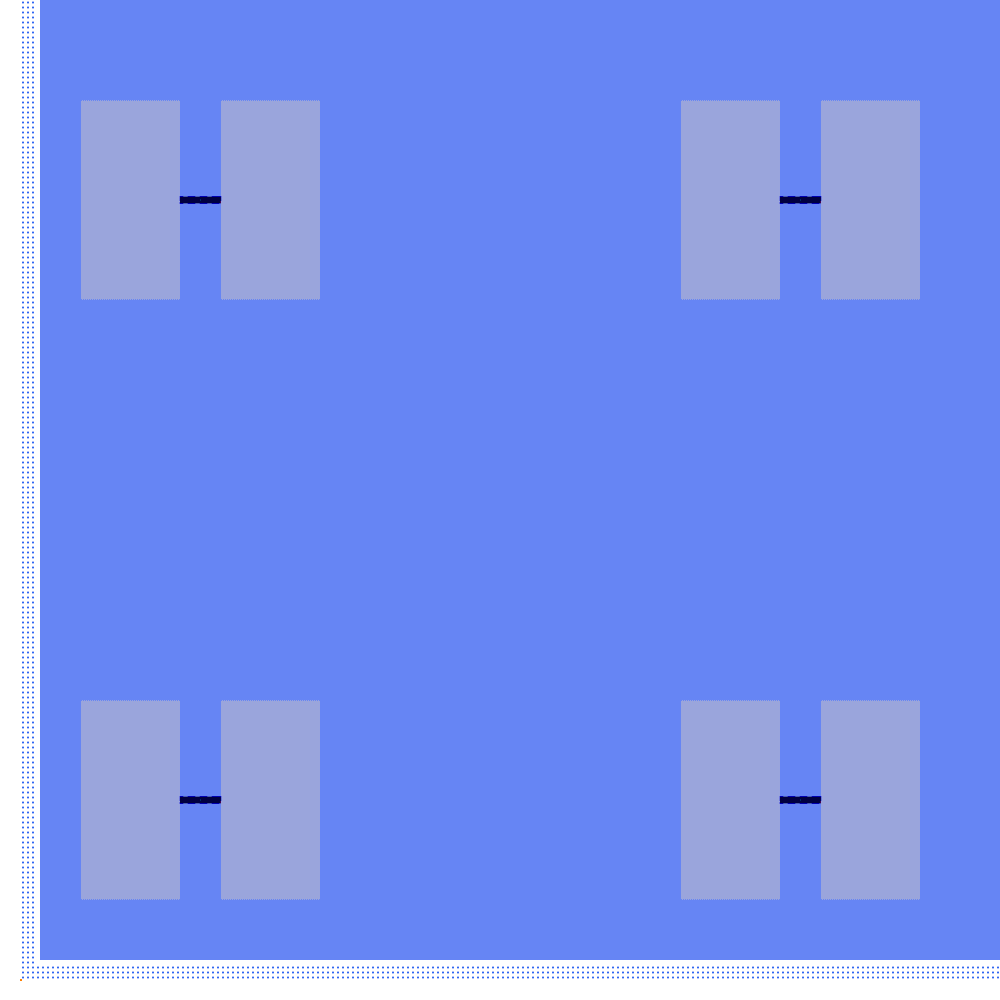

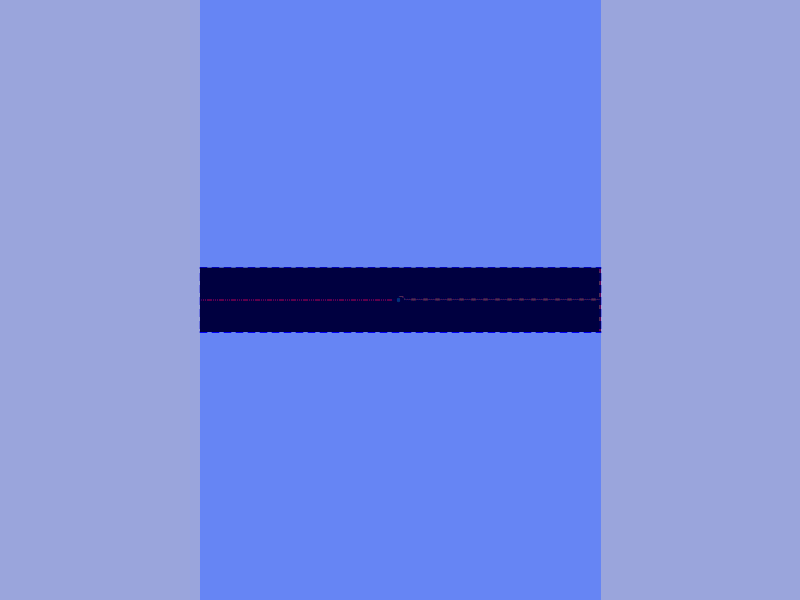

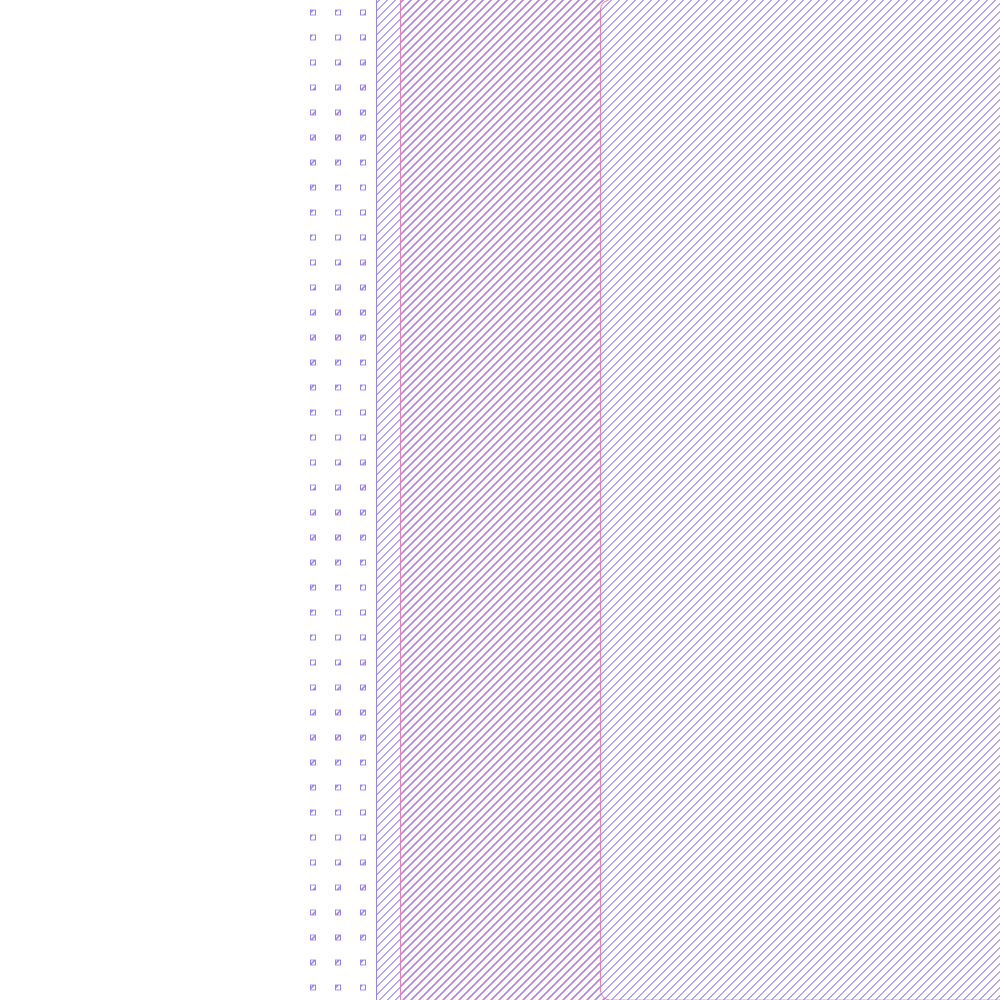

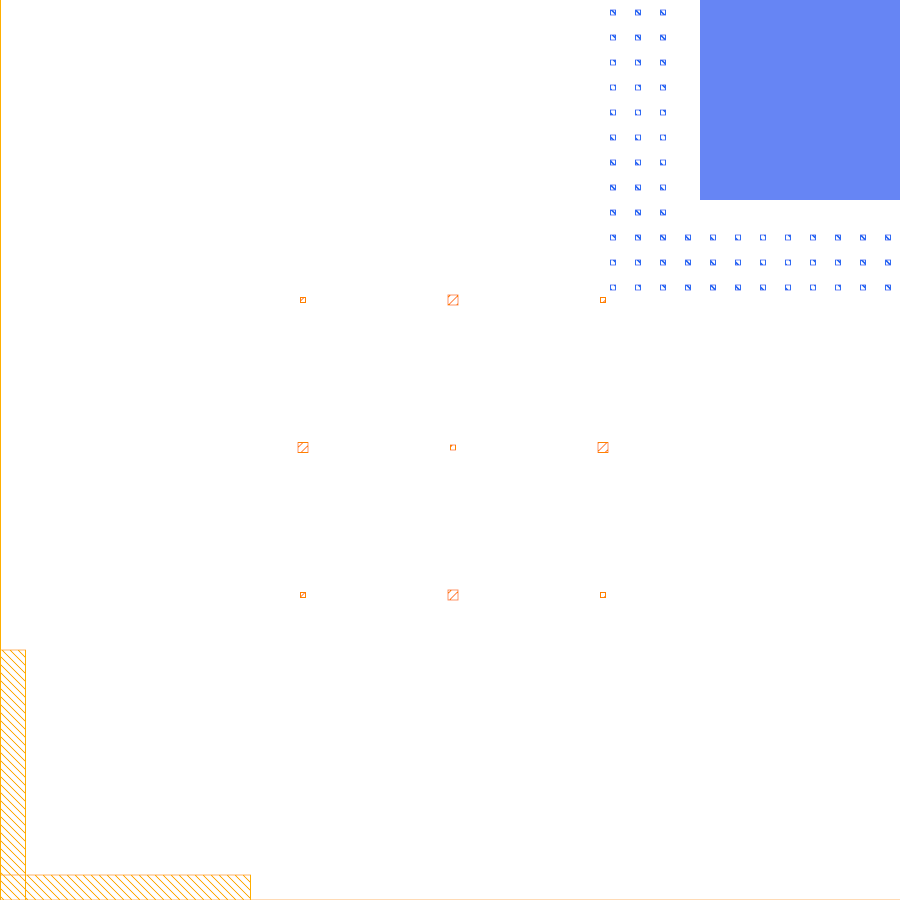

In [16]:
qx, qy = d.data["instances"]["Q_0_0"]["place"]["at"]
show_snapshot(d, OUT / "tut443_10x10_package.png", size=(1200, 1200))
show_snapshot(d, OUT / "tut443_10x10_package_corner.png", box=(qx - 1000, qy - 1000, qx + 4000, qy + 4000),
              size=(1000, 1000), width=480)
show_snapshot(d, OUT / "tut443_10x10_package_gap.png", box=(qx - 200, qy - 150, qx + 200, qy + 150), size=(800, 600),
              width=320)
snap_file(Path("build") / "tut443_10x10_package_fab.oas", OUT / "tut443_10x10_package_cheese.png",
          box=(qx - 1200, qy - 500, qx - 200, qy + 500), size=(1000, 1000), width=420)
show_snapshot(d, OUT / "tut443_10x10_package_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300);

## 16 · Summary

| | |
|---|---|
| matches the source | positions, paddle sizes, gap, orientation, chip size; the no-ground-plane chip (etched, 0.7 mm inside the frame) |
| PDK changes | QCT frame on the 30 mm box; sapphire stack; a trilayer junction drawn in every gap, sized by the PDK rule for 4.05 GHz; PDK cheese band (rim only); content centred (no shift needed); no pads to place |
| differs | the junction (PDK-sized 5.34 nH instead of the paper's 3.63 nH fit); the LOM paddle capacitance (a ground-plane model on a chip without one) |
| LOM (this run) | Q_0_0 4.046 GHz dressed (QuCat 4.116 GHz linear), α −72 MHz; LOM C across the junction 261 fF (paper's fit 173.8 fF); junction 0.63 × 0.6 µm, L_J 5.34 nH, C_J 18.9 fF, R_n 35.6 kΩ; iterate (`pad_height` 1000 → 800 µm): f_q +330 MHz, α −12.8 MHz |
| PDK design warnings | 100 × `pdk_rn` (R_n ≈ 36 kΩ < 40 kΩ) |
| open | the LOM no-ground-plane model (lom request); package modes are not in the LOM; the FEM jobs are exported, not solved (`RUN_FEM = False`) |